# Applied Statistics Assessment: Iris Petal Analysis 

In [1]:
# Numerical arrays and calculations
import numpy as np

# Data loading and grouping
import pandas as pd

# Plotting
import matplotlib.pyplot as plt

# Statistical functions and tests
from scipy import stats

## Problem 1: Exploring Petal Length

Problem 1 involves using the Iris dataset to investigate the distribution of petal length by doing the following:

1. Plot a histogram showing the petal lengths of all 150 flowers.
2. On the same plot, superimpose an apppropriate normal distribution, using the mean and standard deviation calculated from the data.
3. Create seperate histograms for each of the three species, and superimpose an appropriate distribution on each.
4. Report the mean and standard deviation of petal length for the complete dataset and for each species.
5. Describe and compare the distribution observed. And discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

### Loading the data
The Iris dataset that has 150 samples from three types of iris flowers: setosa, versicolor, and virginica.For each flower the dataset records the sepal length, sepal width, petal length, and petal width.

I loaded the data from the local `data` folder of this repository.

In [2]:
# Load the Iris dataset from the data folder
iris = pd.read_csv("data/iris.csv")

# Show the first few rows to check the colmns loaded correctly
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Check the number of rows and the number of flowers per species
print(iris.shape)
print(iris["species"].value_counts())

(150, 5)
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### Histogram of all 150 flowers
To investigate the distribution of petal length, I plot a histogram of all 150 measurements.

I set `density=True` so the bar heights are scaled to a total area of 1. This puts the histogram on the same scale as a probability density function. 

I then overlay a normal curve (`scipy.stats.norm.pdf`) whose mean and standard deviation are calculated from the data. If the data were approximately normal, the curve would follow the shape of the bars.

In [4]:
# Select the petal length column
petal_length = iris["petal_length"]

# Mean and sample standard deviation (ddof=1) of all 150 flowers
mean_all = petal_length.mean()
std_all = petal_length.std(ddof=1)

print(f"Mean: {mean_all:.3f}, standard deviation: {std_all:.3f}")

Mean: 3.758, standard deviation: 1.765


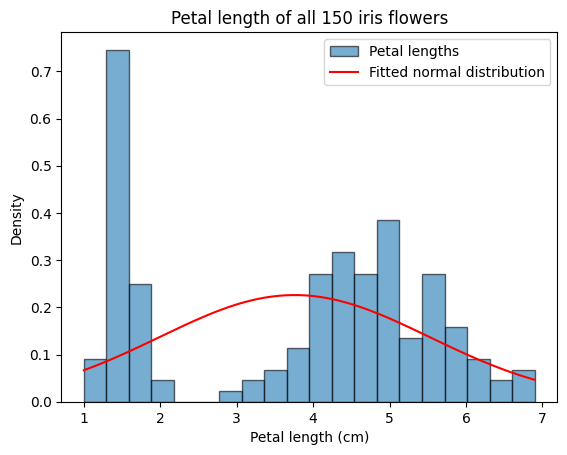

In [5]:
# Histogram of petal length, scaled so the total area is 1
fig, ax = plt.subplots()
ax.hist(petal_length, bins=20, density=True, alpha=0.6, edgecolor="black", label="Petal lengths")

# Evenly spaced x values across the range of the data
x = np.linspace(petal_length.min(), petal_length.max(), 200)

# Normal curve using the mean and standard deviation from the data
ax.plot(x, stats.norm.pdf(x, mean_all, std_all), color="red", label="Fitted normal distribution")
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Density")
ax.set_title("Petal length of all 150 iris flowers")
ax.legend()
plt.show()

The histogram is not a single bell shape. There is a tall, narrow group of flowers with petal lengths between about 1 and 2 cm, a clear gap between roughly 2 and 3 cm where there are almost no flowers, and a second, wider group spread from about 3 to 7 cm, with most flowers between 4 and 6 cm. The fitted normal curve is low and wide, and its peak (near 3.8 cm) falls in the region between the two groups where there are very few flowers. It underestimates the height of the setosa-like spike on the left and does not follow the shape of the main group on the right. A single normal distribution is therefore a poor model for petal length across all 150 flowers. This suggests the data come from more than one population.

## Problem 2: Correlation Between Petal Length and Petal Width

Problem 2 involves investigateing the relationship between petal length and petal width in the Iris dataset by doing the following:

1. Calculating teh Pearson correlation coefficient between petal length adn petal width using all 150 flowers.
2. Create a scatter plot showing the relationship between the two variables, with a line to help illustrate the relationship.
3. Calculate the Pearson correation coefficient seperately for each of the three species.
4. Create a plot showing the relationship between petal length and petal width for each species.
5. Report and compare the correlation coefficients.
6. Explain what the correlation coefficients says about the relationship between petal length and petal width, both for the dataset as a whole and within each species.

## Problem 3: Comparing Species Using t-Tests

Problem 3 involves investigating whether the three iris species differ in their petal length and petal width by doing the following:

1. For each pair of species perform an independant-samples t-test for petal length, petal width.
2. For each test:
   - State the null and alternative hypotheses.
   - Calculate the t-statistic and p-value using scipy.stats.
   - Use a significance level α = 0.05 to decide whether to reject the null hypothesis.
   - Summarise results in a table.
   - Explain what the results say about the differences between the three species.

## Problem 4: Comparing the Species Using ANOVA

Problem 4 involves investigating the differences in petal length and petal width using one-way analysis of variance (ANOVA) for each variable by:

1. Stating the null and alternative hypotheses for a one-way ANOVA.
2. Performing a one-way ANOVA comparing the three species using scipy.stats.
3. Reporting the F-statistic and p-value.
4. Using significant level α = 0.05 determine whether there is evidence that the species have different population means.
5. Explaining what the ANOVA results say and what it doesnt say about the individual species.

## End